# Introduction to Classification

In [ ]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [ ]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


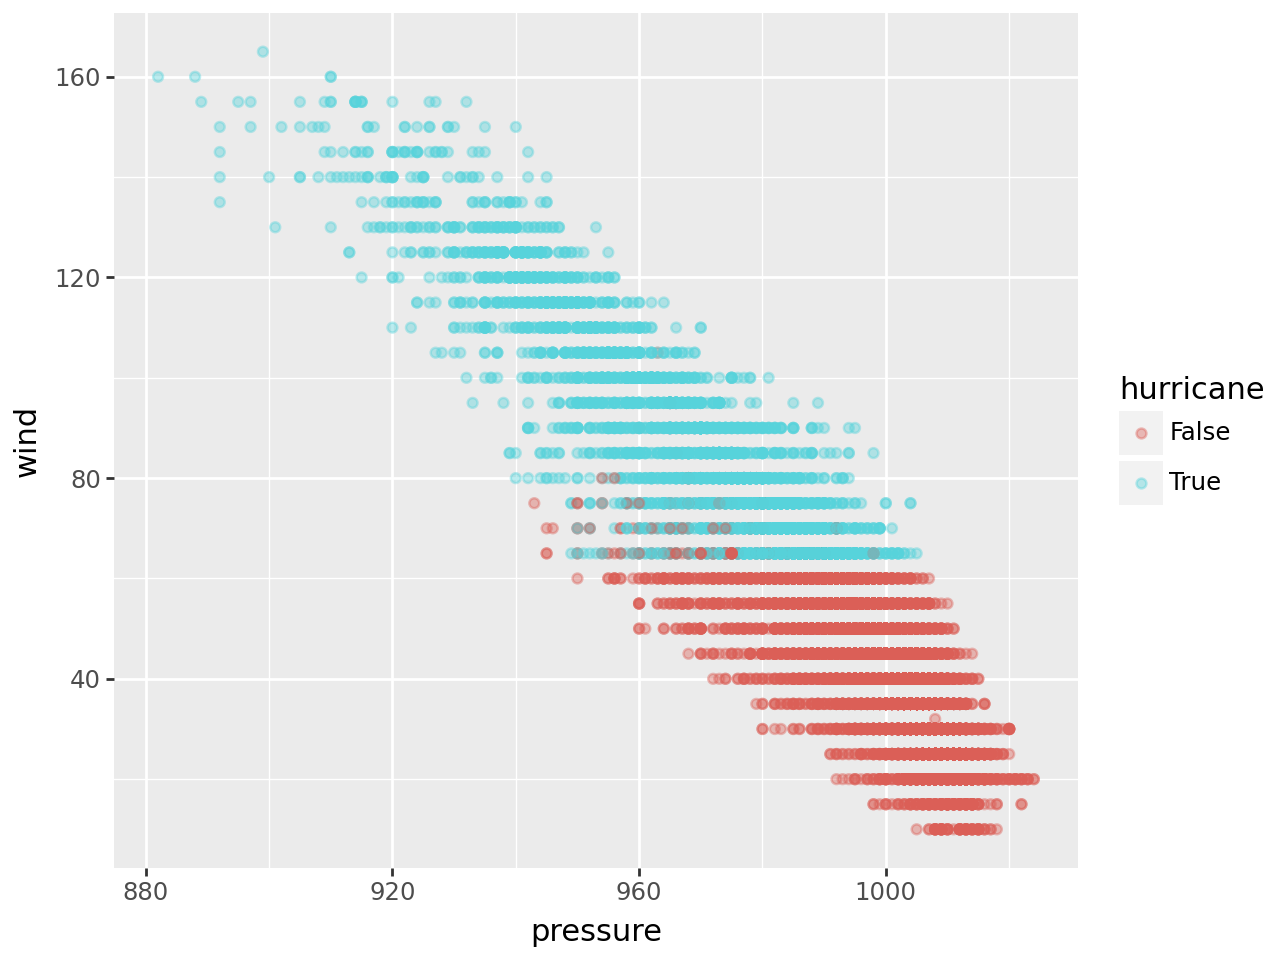

In [ ]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

If wind is more than 60 it is a hurricane, else it is not a hurricane

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [ ]:
predicted_hurricane = df_storms["wind"] > 60
actual_hurricane = df_storms["hurricane"]


TP = ((predicted_hurricane == True) & (actual_hurricane == True)).sum()
FP = ((predicted_hurricane == True) & (actual_hurricane == False)).sum()
TN = ((predicted_hurricane == False) & (actual_hurricane == False)).sum()
FN = ((predicted_hurricane == False) & (actual_hurricane == True)).sum()

accuracy = (TP + TN) / len(df_storms)

precision_hurr = TP / (TP + FP) if (TP + FP) > 0 else 0
recall_hurr = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_hurr = 2 * (precision_hurr * recall_hurr) / (precision_hurr + recall_hurr) if (precision_hurr + recall_hurr) > 0 else 0

precision_non_hurr = TN / (TN + FN) if (TN + FN) > 0 else 0
recall_non_hurr = TN / (TN + FP) if (TN + FP) > 0 else 0
f1_non_hurr = 2 * (precision_non_hurr * recall_non_hurr) / (precision_non_hurr + recall_non_hurr) if (precision_non_hurr + recall_non_hurr) > 0 else 0

print(f"a. Training Accuracy: {accuracy:.2%}")
print(f"b. Training Precision (Hurricane): {precision_hurr:.2%}")
print(f"c. Training Recall (Hurricane): {recall_hurr:.2%}")
print(f"d. Training F1 Score (Hurricane): {f1_hurr:.2%}")
print(f"e. Training Precision (Non-Hurricane): {precision_non_hurr:.2%}")
print(f"f. Training Recall (Non-Hurricane): {recall_non_hurr:.2%}")
print(f"g. Training F1 Score (Non-Hurricane): {f1_non_hurr:.2%}")

a. Training Accuracy: 99.33%
b. Training Precision (Hurricane): 97.34%
c. Training Recall (Hurricane): 100.00%
d. Training F1 Score (Hurricane): 98.65%
e. Training Precision (Non-Hurricane): 100.00%
f. Training Recall (Non-Hurricane): 99.11%
g. Training F1 Score (Non-Hurricane): 99.55%


A. 99.33% of all observations in the training data were correctly classified as either hurricanes or non-hurricanes

B. Out of all observations predicted to be hurricanes (wind > 60), 97.34% of them actually are hurricanes.

C. Out of all actual hurricanes in the dataset, our rule correctly identifies 100.00% of them.

D. The harmonic mean of precision and recall for the hurricane class is 98.65%, reflecting balanced performance on this class.

E. Out of all observations predicted to be non-hurricanes (wind <= 60), 100.00% of them actually are not hurricanes.

F. Out of all actual non-hurricanes in the dataset, our rule correctly identifies 99.11% of them.

G. The harmonic mean of precision and recall for the non-hurricane class is 99.55%.


**DISCUSS WITH YOUR PARTNER.**

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

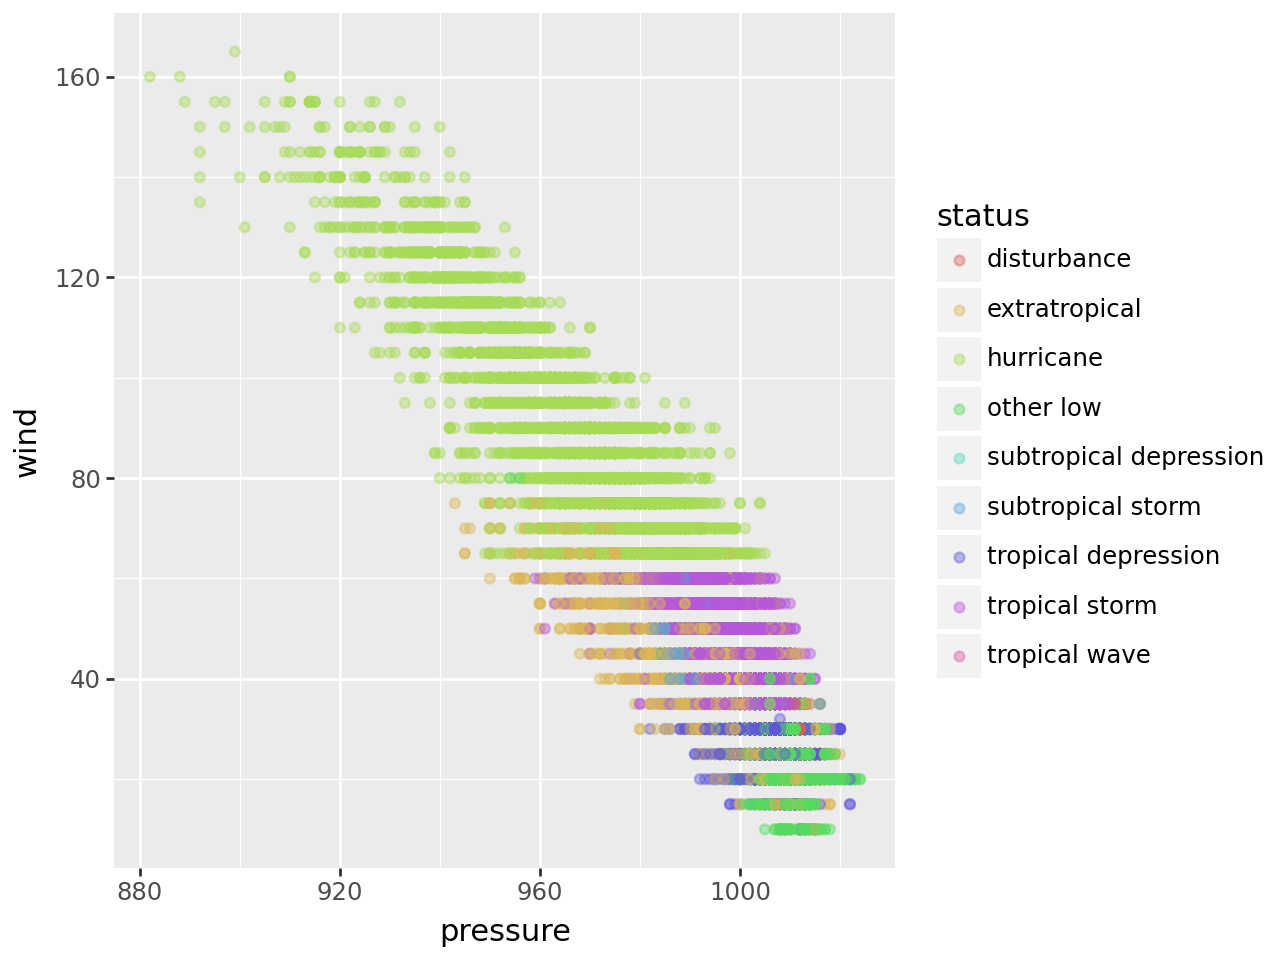

In [ ]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

Probably subtropical depression or storm because these points are pretty surrounded by other classes so it may be hard to predict

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [ ]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X_train = df_titanic[["age", "gender", "class"]]
y_train = df_titanic["survived"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["gender", "class"])
)

pipeline = make_pipeline(
    preprocessor,
    KNeighborsClassifier(n_neighbors=10)
)

pipeline.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(), ['age']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'class'])])),
                ('kneighborsclassifier', KNeighborsClassifier(n_neighbors=10))])

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [ ]:
passengers = pd.DataFrame({
    "age": [20.0, 20.0],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

predictions = pipeline.predict(passengers)

probabilities = pipeline.predict_proba(passengers)

for i, desc in enumerate(["20-year old female in 1st class", "20-year old female in 3rd class"]):
    status = "Survive" if predictions[i] == 1 else "Not Survive"
    prob_survival = probabilities[i][1]
    print(f"{desc}:\n  - Predicted outcome: {status}\n  - Probability of survival: {prob_survival:.1%}\n")

20-year old female in 1st class:
  - Predicted outcome: Survive
  - Probability of survival: 100.0%

20-year old female in 3rd class:
  - Predicted outcome: Not Survive
  - Probability of survival: 20.0%



3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_pred = pipeline.predict(X_train)

precision_surv = precision_score(y_train, y_pred, pos_label=1)
recall_surv = recall_score(y_train, y_pred, pos_label=1)
f1_surv = f1_score(y_train, y_pred, pos_label=1)

print(f"Training Precision (Survivors): {precision_surv:.2%}")
print(f"Training Recall (Survivors): {recall_surv:.2%}")
print(f"Training F1 Score (Survivors): {f1_surv:.2%}")

Training Precision (Survivors): 84.90%
Training Recall (Survivors): 54.57%
Training F1 Score (Survivors): 66.44%


1. Out of all passengers predicted to survive, 84.90% of them actually survived.

2. Out of all passengers who actually survived, our model correctly identified 54.57% of them.

3. The harmonic mean of precision and recall for predicting survivors is 66.44%.

4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_nonsurv = precision_score(y_train, y_pred, pos_label=0)
recall_nonsurv = recall_score(y_train, y_pred, pos_label=0)
f1_nonsurv = f1_score(y_train, y_pred, pos_label=0)

print(f"Training Precision (Non-Survivors): {precision_nonsurv:.2%}")
print(f"Training Recall (Non-Survivors): {recall_nonsurv:.2%}")
print(f"Training F1 Score (Non-Survivors): {f1_nonsurv:.2%}")

Training Precision (Non-Survivors): 81.52%
Training Recall (Non-Survivors): 95.38%
Training F1 Score (Non-Survivors): 87.91%


1. Out of all passengers predicted to not survive, 81.52% of them actually did not survive.

2. Out of all passengers who actually did not survive, our model correctly identified 95.38% of them.

3. The harmonic mean of precision and recall for predicting non-survivors is 87.91%.

5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [ ]:
from sklearn.metrics import precision_score, recall_score

y_prob_surv = pipeline.predict_proba(X_train)[:, 1]

y_pred_new = (y_prob_surv >= 0.8).astype(int)

precision_surv_new = precision_score(y_train, y_pred_new, pos_label=1)
recall_surv_new = recall_score(y_train, y_pred_new, pos_label=1)
precision_nonsurv_new = precision_score(y_train, y_pred_new, pos_label=0)
recall_nonsurv_new = recall_score(y_train, y_pred_new, pos_label=0)

print(f"Threshold 0.8 Metrics:\n")
print(f"  - Precision for survivors: {precision_surv_new:.2%}")
print(f"  - Recall for survivors: {recall_surv_new:.2%}")
print(f"  - Precision for non-survivors: {precision_nonsurv_new:.2%}")
print(f"  - Recall for non-survivors: {recall_nonsurv_new:.2%}\n")

print("Comparison to Threshold 0.5:")
print(f"  - Survivor Precision: Increased from 84.90% to {precision_surv_new:.2%}.")
print(f"  - Survivor Recall: Decreased from 54.57% to {recall_surv_new:.2%}.")
print(f"  - Non-Survivor Precision: Decreased from 81.52% to {precision_nonsurv_new:.2%}.")
print(f"  - Non-Survivor Recall: Increased from 95.38% to {recall_nonsurv_new:.2%}.")

Threshold 0.8 Metrics:

  - Precision for survivors: 91.57%
  - Recall for survivors: 42.76%
  - Precision for non-survivors: 78.27%
  - Recall for non-survivors: 98.13%

Comparison to Threshold 0.5:
  - Survivor Precision: Increased from 84.90% to 91.57%.
  - Survivor Recall: Decreased from 54.57% to 42.76%.
  - Non-Survivor Precision: Decreased from 81.52% to 78.27%.
  - Non-Survivor Recall: Increased from 95.38% to 98.13%.


6\. Plot the precision-recall curve for the survivors. Interpret what you see.

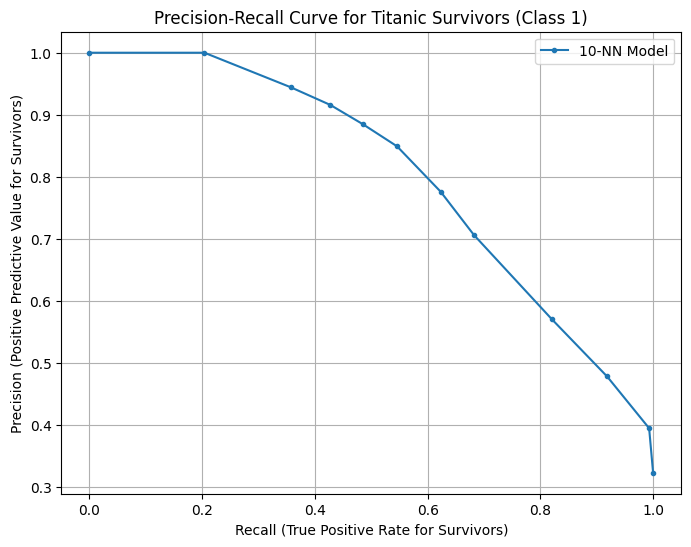

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

y_prob_surv = pipeline.predict_proba(X_train)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, y_prob_surv, pos_label=1)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='10-NN Model')
plt.xlabel('Recall (True Positive Rate for Survivors)')
plt.ylabel('Precision (Positive Predictive Value for Survivors)')
plt.title('Precision-Recall Curve for Titanic Survivors (Class 1)')
plt.grid(True)
plt.legend()
plt.show()

The curve shows the classic trade-off between precision and recall: as we increase recall (identifying a higher percentage of actual survivors), precision tends to decrease (more false positives are introduced, meaning some predicted survivors actually died). The curve stays relatively high (above 80% precision) for recalls up to about 55%, but experiences a more noticeable drop-off beyond that point when trying to capture more survivors.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

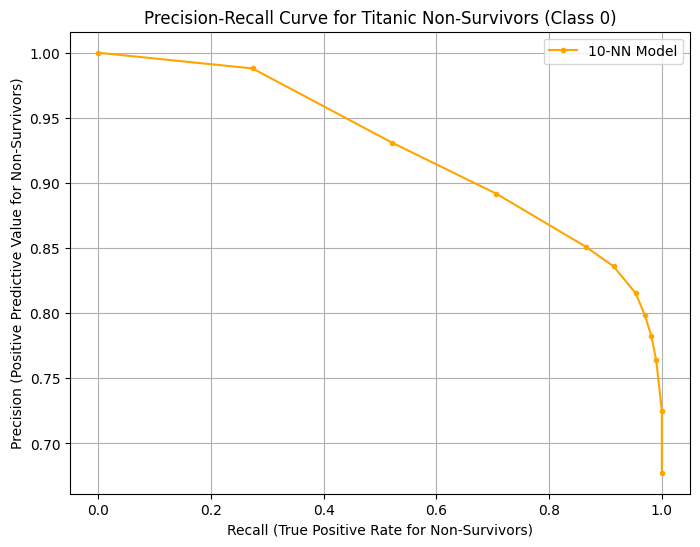

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

y_prob_nonsurv = 1 - y_prob_surv

precision_ns, recall_ns, thresholds_ns = precision_recall_curve(y_train, y_prob_nonsurv, pos_label=0)

plt.figure(figsize=(8, 6))
plt.plot(recall_ns, precision_ns, marker='.', color='orange', label='10-NN Model')
plt.xlabel('Recall (True Positive Rate for Non-Survivors)')
plt.ylabel('Precision (Positive Predictive Value for Non-Survivors)')
plt.title('Precision-Recall Curve for Titanic Non-Survivors (Class 0)')
plt.grid(True)
plt.legend()
plt.show()

The curve for non-survivors remains remarkably high overall compared to the survivor class. Even when recall is extremely high (e.g., above 95%, meaning we correctly identify almost all actual non-survivors), precision still holds steady around 80%. This shows that the 10-NN model is highly reliable at identifying passengers who did not survive with minimal false positives.